# Demand Forecasting: next-day hourly demand with LightGBM
**Goal:** forecast hourly demand **24 hours ahead** so operations can plan capacity (staff, stock, liquidity), comparing ML against simple baselines.

**Data:** UCI Bike Sharing dataset, hourly rentals in Washington D.C., 2011–2012 (~17k hours), with calendar and weather features.

**Setup (realistic):**
- Time-based split: train → Jan 2011–Jun 2012, validation → Jul–Sep 2012, test → Oct–Dec 2012.
- Forecast is made a day in advance, so only lags of **24 h or more** are allowed (no peeking at the last few hours).
- Metrics: MAE, RMSE and **WAPE** (MAPE breaks when night-time demand is near zero).

In [1]:
# Run first. LightGBM is preinstalled in Colab; this just makes sure.
!pip -q install lightgbm

In [2]:
import io, zipfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

URL = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
raw = pd.read_csv(z.open('hour.csv'))
print(raw.shape); raw.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 1. Build a clean hourly time series
The raw file skips some hours (system outages / zero demand). Lags must be in true hours, so we re-index to a complete hourly calendar and fill missing demand with 0.

missing hours filled: 165


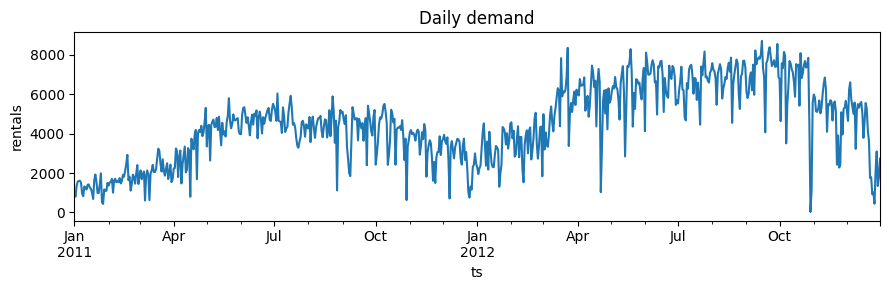

In [3]:
raw['ts'] = pd.to_datetime(raw['dteday']) + pd.to_timedelta(raw['hr'], unit='h')
full = pd.date_range(raw['ts'].min(), raw['ts'].max(), freq='h')
df = raw.set_index('ts').reindex(full)
print('missing hours filled:', int(df['cnt'].isna().sum()))
df['cnt'] = df['cnt'].fillna(0)
df[['holiday','workingday','weathersit','temp','atemp','hum','windspeed']] = \
    df[['holiday','workingday','weathersit','temp','atemp','hum','windspeed']].ffill()
df.index.name = 'ts'
df = df[['cnt','holiday','workingday','weathersit','temp','atemp','hum','windspeed']].copy()

df['cnt'].resample('D').sum().plot(figsize=(9,3), title='Daily demand'); plt.ylabel('rentals'); plt.tight_layout(); plt.show()

## 2. Feature engineering (all known 24 h in advance)

In [4]:
def make_features(d):
    d = d.copy()
    d['hour'], d['dow'], d['month'] = d.index.hour, d.index.dayofweek, d.index.month
    d['is_weekend'] = (d['dow'] >= 5).astype(int)
    d['trend'] = np.arange(len(d))                       # captures year-on-year growth
    for L in [24, 48, 168, 336]:                          # same hour 1, 2 days and 1, 2 weeks ago
        d[f'lag_{L}'] = d['cnt'].shift(L)
    s = d['cnt'].shift(24)
    d['roll_mean_24'] = s.rolling(24).mean()              # average of the day before
    d['roll_mean_168'] = s.rolling(168).mean()            # weekly level
    d['roll_std_168'] = s.rolling(168).std()
    d['same_hour_mean_4w'] = (d['cnt'].shift(168) + d['cnt'].shift(336) + d['cnt'].shift(504) + d['cnt'].shift(672)) / 4
    return d.dropna()

data = make_features(df)
WEATHER = ['weathersit','temp','atemp','hum','windspeed']
FEATS_ALL = [c for c in data.columns if c != 'cnt']
FEATS_NO_WEATHER = [c for c in FEATS_ALL if c not in WEATHER]

train = data[:'2012-06-30']; val = data['2012-07-01':'2012-09-30']; test = data['2012-10-01':]
print(len(train), len(val), len(test))

12456 2208 2208


## 3. Metrics and baselines
A model is only useful if it beats simple rules. Baselines: *same hour yesterday* and *same hour last week* (seasonal naive).

In [5]:
def wape(y, p): return np.abs(y - p).sum() / np.abs(y).sum()
results, preds = [], {}
def evaluate(name, y, p):
    p = np.clip(p, 0, None)
    r = dict(model=name, MAE=mean_absolute_error(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), WAPE=wape(y, p))
    results.append(r); preds[name] = p
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})

y_test = test['cnt'].values
evaluate('Naive: same hour yesterday', y_test, test['lag_24'].values)
evaluate('Naive: same hour last week', y_test, test['lag_168'].values)
evaluate('Naive: 4-week same-hour average', y_test, test['same_hour_mean_4w'].values)

{'model': 'Naive: same hour yesterday', 'MAE': 77.203, 'RMSE': np.float64(128.877), 'WAPE': np.float64(0.359)}
{'model': 'Naive: same hour last week', 'MAE': 75.917, 'RMSE': np.float64(129.767), 'WAPE': np.float64(0.353)}
{'model': 'Naive: 4-week same-hour average', 'MAE': 63.747, 'RMSE': np.float64(112.209), 'WAPE': np.float64(0.296)}


## 4. LightGBM
Trained on log(1+demand) to handle skew; early stopping on the validation period; then refit on train+validation with the chosen number of trees.

In [6]:
PARAMS = dict(objective='regression', learning_rate=0.03, num_leaves=63, min_child_samples=20,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, seed=42)

def fit_lgb(feats, name, params=PARAMS, target_log=True):
    tf = (lambda v: np.log1p(v)) if target_log else (lambda v: v)
    m = lgb.train(params, lgb.Dataset(train[feats], tf(train['cnt'])), num_boost_round=3000,
                  valid_sets=[lgb.Dataset(val[feats], tf(val['cnt']))],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    best = m.best_iteration
    trval = pd.concat([train, val])
    final = lgb.train(params, lgb.Dataset(trval[feats], tf(trval['cnt'])), num_boost_round=best)
    p = final.predict(test[feats])
    if target_log: p = np.expm1(p)
    print(f'{name}: best trees = {best}')
    evaluate(name, y_test, p)
    return final

model_nw = fit_lgb(FEATS_NO_WEATHER, 'LightGBM (calendar + lags)')
model = fit_lgb(FEATS_ALL, 'LightGBM (+ weather)')

LightGBM (calendar + lags): best trees = 113
{'model': 'LightGBM (calendar + lags)', 'MAE': 55.731, 'RMSE': np.float64(90.897), 'WAPE': np.float64(0.259)}
LightGBM (+ weather): best trees = 233
{'model': 'LightGBM (+ weather)', 'MAE': 44.491, 'RMSE': np.float64(70.527), 'WAPE': np.float64(0.207)}


## 5. Results

In [7]:
res = pd.DataFrame(results).set_index('model').round(3)
display(res); res.to_csv('results.csv')
best_name = res['WAPE'].idxmin()
base = res.loc['Naive: same hour last week', 'WAPE']
print(f"Best: {best_name} -> WAPE {res.loc[best_name,'WAPE']:.3f}, "
      f"{(1 - res.loc[best_name,'WAPE']/base)*100:.0f}% lower error than the seasonal-naive baseline")

,MAE,RMSE,WAPE
model,,,
Naive: same hour yesterday,77.203,128.877,0.359
Naive: same hour last week,75.917,129.767,0.353
Naive: 4-week same-hour average,63.747,112.209,0.296
LightGBM (calendar + lags),55.731,90.897,0.259
LightGBM (+ weather),44.491,70.527,0.207


Best: LightGBM (+ weather) -> WAPE 0.207, 41% lower error than the seasonal-naive baseline


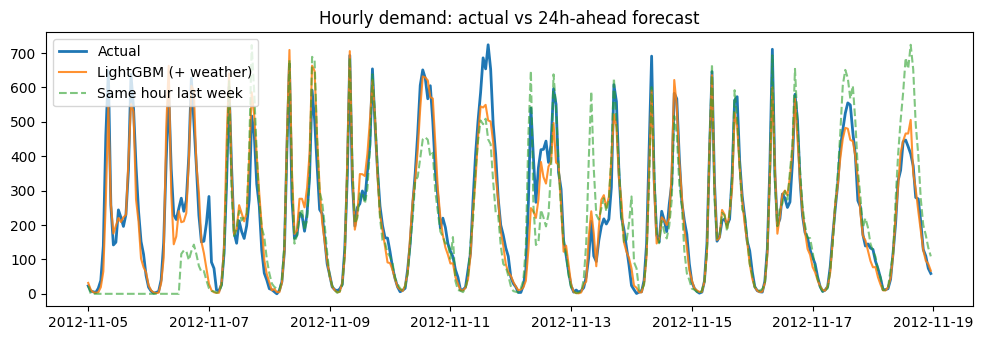

In [8]:
# Actual vs forecast for two weeks of the test period
w = slice('2012-11-05', '2012-11-18')
plt.figure(figsize=(10,3.5))
plt.plot(test.loc[w].index, test.loc[w, 'cnt'], label='Actual', lw=2)
plt.plot(test.loc[w].index, pd.Series(preds[best_name], index=test.index).loc[w], label=best_name, alpha=.85)
plt.plot(test.loc[w].index, test.loc[w, 'lag_168'], label='Same hour last week', alpha=.6, ls='--')
plt.title('Hourly demand: actual vs 24h-ahead forecast'); plt.legend(); plt.tight_layout()
plt.savefig('forecast_vs_actual.png', dpi=150); plt.show()

## 6. What drives the forecast, and where it fails

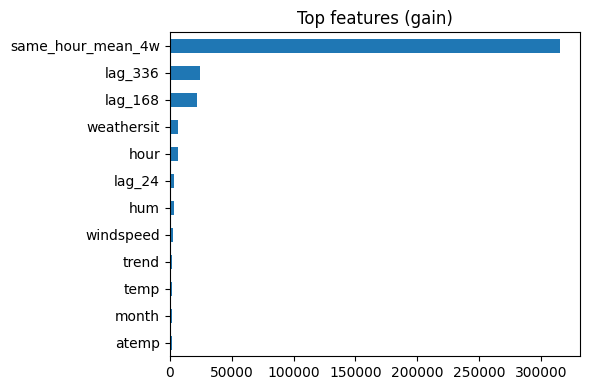

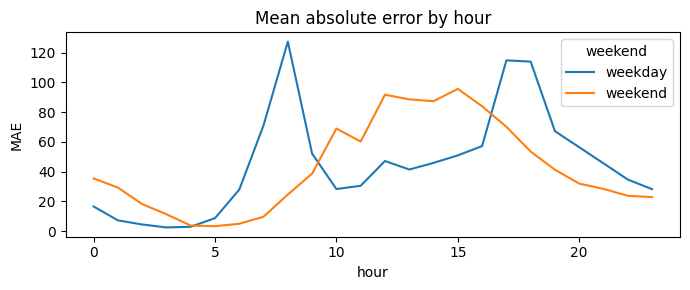

Worst-forecast days (often holidays or extreme weather):


,actual,pred,ape
ts,,,
2012-10-29,22.0,2018.56,90.75
2012-12-26,441.0,1727.89,2.92
2012-12-24,920.0,2854.64,2.10
2012-10-30,1096.0,2656.36,1.42
2012-12-25,1013.0,2343.85,1.31


In [9]:
imp = pd.Series(model.feature_importance('gain'), index=FEATS_ALL).sort_values()
imp.tail(12).plot.barh(figsize=(6,4), title='Top features (gain)'); plt.tight_layout(); plt.savefig('feature_importance.png', dpi=150); plt.show()

err = pd.DataFrame({'abs_err': np.abs(y_test - preds[best_name]), 'hour': test.index.hour,
                    'weekend': test['is_weekend'].values})
err.groupby(['hour','weekend'])['abs_err'].mean().unstack().rename(columns={0:'weekday',1:'weekend'}) \
   .plot(figsize=(7,3), title='Mean absolute error by hour'); plt.ylabel('MAE'); plt.tight_layout()
plt.savefig('error_by_hour.png', dpi=150); plt.show()

daily = pd.DataFrame({'actual': y_test, 'pred': preds[best_name]}, index=test.index).resample('D').sum()
daily['ape'] = (daily['pred'] - daily['actual']).abs() / daily['actual'].clip(lower=1)
print('Worst-forecast days (often holidays or extreme weather):'); display(daily.sort_values('ape', ascending=False).head(5).round(2))

## 7. Prediction intervals (for capacity planning)
A single number isn't enough for planning: we train quantile models for the 10th and 90th percentiles and check how often the truth falls inside.

80% interval coverage on test: 63.7% (target 80%), average width 106 rentals


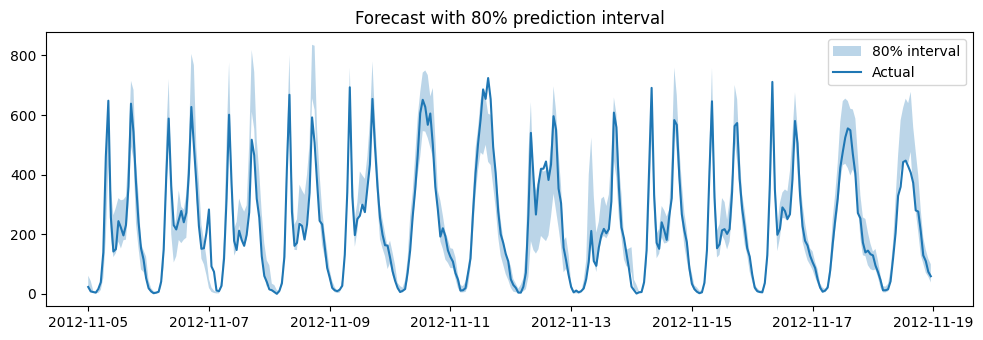

In [10]:
q = {}
for a in [0.1, 0.9]:
    pq = dict(PARAMS, objective='quantile', alpha=a)
    trval = pd.concat([train, val])
    m = lgb.train(pq, lgb.Dataset(trval[FEATS_ALL], trval['cnt']), num_boost_round=800)
    q[a] = np.clip(m.predict(test[FEATS_ALL]), 0, None)
lo, hi = np.minimum(q[0.1], q[0.9]), np.maximum(q[0.1], q[0.9])
coverage = ((y_test >= lo) & (y_test <= hi)).mean()
print(f'80% interval coverage on test: {coverage:.1%} (target 80%), average width {np.mean(hi - lo):.0f} rentals')

plt.figure(figsize=(10,3.5))
idx = test.loc[w].index; m_ = test.index.isin(idx)
plt.fill_between(idx, lo[m_], hi[m_], alpha=.3, label='80% interval')
plt.plot(idx, y_test[m_], label='Actual', lw=1.5)
plt.title('Forecast with 80% prediction interval'); plt.legend(); plt.tight_layout()
plt.savefig('prediction_interval.png', dpi=150); plt.show()

## 8. Summary (fill in with YOUR numbers)
- **Problem:** forecast hourly demand 24 h ahead for capacity planning.
- **Approach:** leak-free lag/rolling features, time-based split, log target, early stopping, LightGBM vs naive baselines; quantile models for uncertainty.
- **Result:** best model WAPE ___ vs ___ for seasonal naive (___% lower error); 80% interval coverage ___.
- **Insights:** biggest errors at commute peaks / holidays / bad weather; weather features helped by ___.
- **Caveat:** weather here is the *observed* weather; in production you'd use weather *forecasts*, so the calendar+lags model is the honest lower bound.
- **Next steps:** holiday calendar features, hierarchical forecasts (station level), monitoring + retraining.